# 06 · 稳定性、SQL 核对与业务情景

## 本页要回答什么

当前模型结果对开发样本规模和划分方式有多敏感？SQL 汇总能否与 Python 指标核对？在明确的成本/价值假设下，业务决策需要什么额外证据？

## 代码导航

- 稳定性：run_stability.py → criteo_uplift/stability.py。
- 冻结预测的指标扩展：scripts/run_metrics_extension.py → criteo_uplift/evaluation.py。
- SQL 核对：scripts/run_sql_audit.py → criteo_uplift/sql_audit.py。
- 样本量与经济情景：criteo_uplift/planning.py 的 plan_policy_ab()、cost_value_scenario()。
- 主要结果目录：stability_v1/、metrics_v2/、sql_audit_v1/。

这些是已经运行完成的扩展产物，本页不会重训或根据测试结果更换模型。稳定性分析排除旧测试行，但此前已看过旧测试结果，因此不能包装成全新独立确认。

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'criteo_uplift').is_dir())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from criteo_uplift.runtime import configure_runtime
configure_runtime()
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from criteo_uplift.pipeline_io import result_directory
FIG = ROOT/'artifacts/extension_figures'
FIG.mkdir(exist_ok=True)


In [2]:
ST = result_directory('stability_v1', ROOT)
report = json.loads((ST / 'report.json').read_text())
long = pd.read_csv(ST / 'longmetrics.csv')
agg = pd.read_csv(ST / 'aggregate.csv')
audit = pd.read_csv(ST / 'split_audit.csv')

display({
    key: report[key]
    for key in [
        'experiments', 'fitted_models', 'development_n',
        'old_test_n_excluded', 'all_old_test_row_overlaps_zero',
        'all_group_split_feature_overlaps_zero'
    ]
})
audit_columns = [
    'split_method', 'train_n', 'validation_n',
    'train_old_test_overlap', 'validation_old_test_overlap',
    'feature_group_overlap'
]
missing_columns = [column for column in audit_columns if column not in audit.columns]
if missing_columns:
    raise ValueError(f"split_audit.csv 缺少必需字段：{', '.join(missing_columns)}")
if 'row_overlap' in audit.columns:
    audit_columns.append('row_overlap')
display(audit[audit_columns])

cols = [
    'split_method', 'training_fraction', 'policy',
    'incremental_per_100k_mean', 'incremental_per_100k_std',
    'vs_propensity_per_100k_mean', 'train_control_events_min',
    'train_control_events_max'
]
display(agg[cols].sort_values(['split_method', 'training_fraction', 'policy']))

{'experiments': 12,
 'fitted_models': 48,
 'development_n': 800000,
 'old_test_n_excluded': 200000,
 'all_old_test_row_overlaps_zero': True,
 'all_group_split_feature_overlaps_zero': True}

,split_method
0,row_stratified
1,row_stratified
2,row_stratified
3,feature_group
4,row_stratified
5,row_stratified
6,row_stratified
7,feature_group
8,row_stratified
9,row_stratified


,split_method,training_fraction,policy,incremental_per_100k_mean,incremental_per_100k_std,vs_propensity_per_100k_mean,train_control_events_min,train_control_events_max
23,feature_group,1.00,propensity,146.032995,5.484177,0.000000,163,169
18,feature_group,1.00,random,28.732907,0.570554,-117.300088,163,169
19,feature_group,1.00,s_logistic,148.792021,5.349990,2.759026,163,169
20,feature_group,1.00,t_logistic,134.838641,4.288820,-11.194355,163,169
21,feature_group,1.00,t_xgboost,127.301159,6.073088,-18.731836,163,169
22,feature_group,1.00,x_xgboost,119.100833,3.467040,-26.932163,163,169
5,row_stratified,0.25,propensity,126.593822,5.401909,0.000000,40,41
0,row_stratified,0.25,random,25.060479,0.386261,-101.533343,40,41
1,row_stratified,0.25,s_logistic,124.768235,3.799729,-1.825587,40,41
2,row_stratified,0.25,t_logistic,98.262244,20.575630,-28.331578,40,41


## 1. 训练规模与划分方式的敏感性

**实现位置：** criteo_uplift/stability.py；结果目录 stability_v1/。

三个 seed × 25% / 50% / 100% 的嵌套训练子集使用固定验证集，误差棒为三个划分的样本标准差，不是 95% CI；这些配置共享数据，不能视为独立实验。

另做三个全规模特征组隔离划分：相同 float32 匿名特征向量不跨 train/validation，保留全部行。这不是用户 ID 分组，也不能证明真实用户无泄漏。组隔离改变验证分布，不能直接用两种切分的指标高低宣称某一种更优。

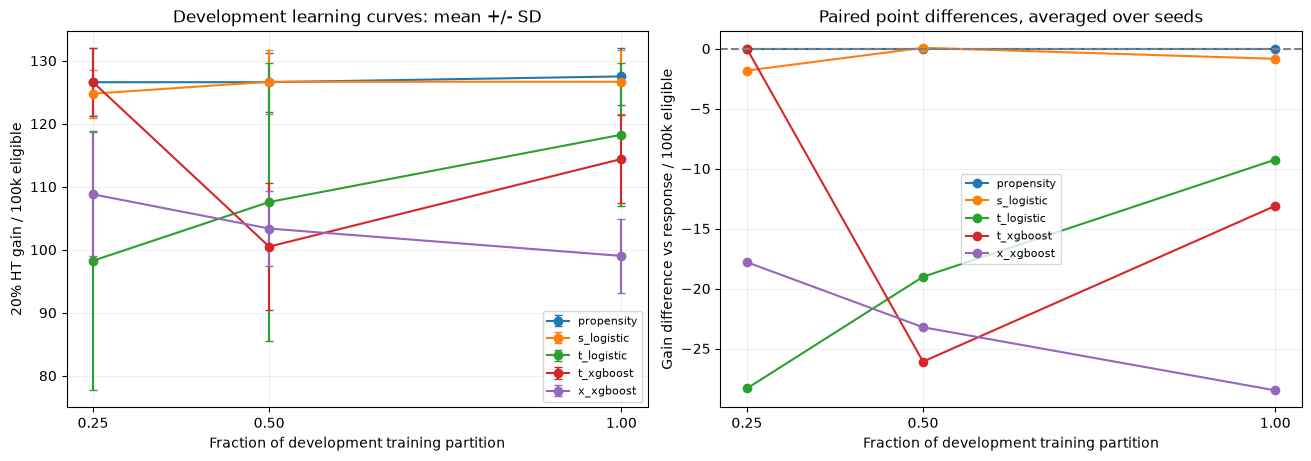

X-Learner 胜过 response 的开发配置数: 0 / 12
注意：25% 规模 T-XGBoost 和 response 指标相等；选择频率含固定候选顺序的 tie-break，不能当作获胜证据。


In [3]:
fig,axes=plt.subplots(1,2,figsize=(13,4.5),layout='constrained')
for name in ['propensity','s_logistic','t_logistic','t_xgboost','x_xgboost']:
    a=agg[(agg.split_method=='row_stratified') & (agg.policy==name)].sort_values('training_fraction')
    axes[0].errorbar(a.training_fraction,a.incremental_per_100k_mean,yerr=a.incremental_per_100k_std,marker='o',capsize=3,label=name)
    axes[1].plot(a.training_fraction,a.vs_propensity_per_100k_mean,'o-',label=name)
axes[0].set(title='Development learning curves: mean +/- SD',ylabel='20% HT gain / 100k eligible')
axes[1].axhline(0,color='gray',ls='--')
axes[1].set(title='Paired point differences, averaged over seeds',ylabel='Gain difference vs response / 100k eligible')
for ax in axes:
    ax.set_xlabel('Fraction of development training partition');ax.set_xticks([.25,.5,1]);ax.grid(alpha=.2);ax.legend(fontsize=8)
fig.savefig(FIG/'stability_learning_curves.png',dpi=160);plt.show()
x=long[long.policy=='x_xgboost']
print('X-Learner 胜过 response 的开发配置数:',int((x.vs_propensity_per_100k>0).sum()),'/',len(x))
print('注意：25% 规模 T-XGBoost 和 response 指标相等；选择频率含固定候选顺序的 tie-break，不能当作获胜证据。')

### 1.1 重复与精度：隔离敏感性分析说明

[Notebook 01](01_data_understanding.ipynb) 展示行号互斥、原始内容重复与 float32 舍入新增匹配的事实。本节回答“改变相同内容跨集合出现的方式后，结果如何变化”，不把内容匹配直接称为用户泄漏。

现有两种隔离分析需要分开理解：

| 分析 | 按什么分组 | 数据范围及已有证据 | 不能据此声称 |
|---|---|---|---|
| 本页前面的开发期特征组隔离（stability_v1） | 12 个 float32 处理前特征的哈希 | 排除旧 test 后的 80 万开发行；3 个 seed 的组划分中，train / validation 的特征组交集为零 | 真实用户隔离、原测试集已消除重叠或新的独立测试验证 |
| 2026-10-20 原始完整记录隔离 | 原始 float64 全部 16 个字段的精确相等组，不含 row_id | 同一批 100 万行重新分组划分为 train / validation / test；保留全部行，三对集合的原始完整记录匹配均为零 | 所有 float32 相同输入均已隔离，或这是不依赖结果标签的正式用户分组方案 |

第二项是**已看过原测试结果后的事后内容重复敏感性分析**。它使用包含 treatment 和结果标签的完整记录定义内容组，只用于核验可观测重复；不能将这种分组当作未来部署时的用户标识或基于处理前信息的标准划分规则。以下表格摘自当时已完成的归档，本次没有重新训练、重新选型或覆盖主实验。

#### 原始完整记录隔离后，模型输入仍可能重合

| Train → Test 的内容匹配口径 | Baseline | 原始完整记录隔离后 |
|---|---:|---:|
| 原始 float64 完整记录 | 1,943（0.9715%） | 0（0.0000%） |
| float32 建模特征 | 3,712（1.8560%） | 1,797（0.8985%） |
| float32 特征 + 四个标签 | 2,733（1.3665%） | 752（0.3760%） |

分母均为相应方案的 200,000 条测试行，每条测试行至多计一次。完整记录隔离只保证消除原始 16 字段相等组的跨集合重复；它不保证消除原始特征相同但标签不同的记录，也不保证消除 float32 舍入新增的相同输入。这与前面的“float32 特征组隔离”不是同一种方法。

#### 固定模型配置下的结果变化

两方案均使用 float32 建模特征、相同候选模型参数，仅在各自 train 拟合并用各自 validation 选型。下表列出 20% 预算 HT 增量点估计，单位为每 10 万名全部待选人群：

| 候选策略 | Baseline | 原始完整记录隔离后 |
|---|---:|---:|
| propensity | 117.228 | 118.806 |
| s_logistic | 123.325 | 123.727 |
| t_logistic | 126.329 | 99.621 |
| t_xgboost | 95.353 | 106.153 |
| x_xgboost | 110.116 | 96.746 |

归档中 Baseline 的验证集获选策略为 propensity，完整记录隔离方案的验证集获选策略为 s_logistic；这是各补充方案内部的验证选择，**不改变正式主实验已冻结的 propensity 策略**。各候选策略的点估计有升有降，不能根据测试表格重新选赢家。

#### 这些证据可以与不可以支持什么

- 可以确认原始内容重复与数值精度重合是不同现象，并检查指定相等组是否跨集合出现；不能将相同匿名向量认定为同一用户，也不能因缺少身份信息就断言重复没有影响。
- 完整记录隔离同时改变了训练、验证、测试成员及随机分组方式；这不是只改变“泄漏”一个因素的对照，因此表中差值不能解释为泄漏造成的乐观偏差。前面的开发期组划分同样改变特征支持，不能仅按指标高低判断哪种划分更优。
- 完整记录隔离方案按构造保持了各集合 T×conversion 计数，所以其 ATE 相同；这不是“重复对模型没有影响”的证据。两方案训练精度均为 float32，也不是 float32 与 float64 模型效果对照。
- 这是一次事后重分组分析，没有新的独立确认，也没有跨方案差值检验。已有按行 bootstrap 区间不覆盖重新训练、选型、切分变化或未知用户依赖，不是组稳健区间；不能凭两条区间是否重叠判断差异。
- 当前保留主实验，不自动去重，不仅为了降低重叠数字而改精度。用户级独立性、真实事件来源和特征生成时点仍无法由匿名字段验证。

来源为 2026-10-20 归档中的 `sensitivity_protocol.json`、`sensitivity_overlap.csv`、`sensitivity_policies.csv` 和 `selections.json`；此处只嵌入已有聚合结果，阅读不依赖本机 artifacts 目录。来源文件指纹记录在本单元元数据中。Notebook 01 负责说明数据事实，本节负责说明已有影响评估及其边界。


## 2. 冻结预测的 v2 指标与配对区间

**实现位置：** scripts/run_metrics_extension.py 调用 evaluation.py；结果目录 metrics_v2/。

该扩展对已经保存的预测重算指标，不重新训练或重新选择模型。区间是固定模型、固定分配概率和给定臂样本量条件下的逐项区间，不包含训练与选型不确定性，也不是多指标同时区间。

,policy,auuc_plugin,auuc_ht,qini_score_traditional,qini_ht
0,s_logistic,0.001132,0.001196,0.000444,0.000580
1,t_logistic,0.001148,0.001210,0.000458,0.000595
2,t_xgboost,0.000912,0.000972,0.000256,0.000357
3,x_xgboost,0.001057,0.001099,0.000379,0.000484
4,propensity,0.001137,0.001198,0.000448,0.000583


,metric,policy,estimate,ci_low,ci_high,vs_propensity,vs_propensity_ci_low,vs_propensity_ci_high
0,auuc_ht,s_logistic,0.001196,0.000637,0.001650,-0.000003,-0.000023,0.000017
1,qini_ht,s_logistic,0.000580,0.000302,0.000808,-0.000003,-0.000023,0.000017
2,auuc_plugin,s_logistic,0.001132,0.000565,0.001590,-0.000006,-0.000030,0.000016
3,auuc_plugin_centered,s_logistic,0.000516,0.000238,0.000749,-0.000006,-0.000030,0.000016
4,qini_score_traditional,s_logistic,0.000444,0.000204,0.000644,-0.000004,-0.000025,0.000014
5,auuc_ht,t_logistic,0.001210,0.000720,0.001611,0.000012,-0.000130,0.000183
6,qini_ht,t_logistic,0.000595,0.000372,0.000804,0.000012,-0.000130,0.000183
7,auuc_plugin,t_logistic,0.001148,0.000649,0.001574,0.000011,-0.000128,0.000181
8,auuc_plugin_centered,t_logistic,0.000533,0.000314,0.000745,0.000011,-0.000128,0.000181
9,qini_score_traditional,t_logistic,0.000458,0.000270,0.000641,0.000010,-0.000108,0.000155


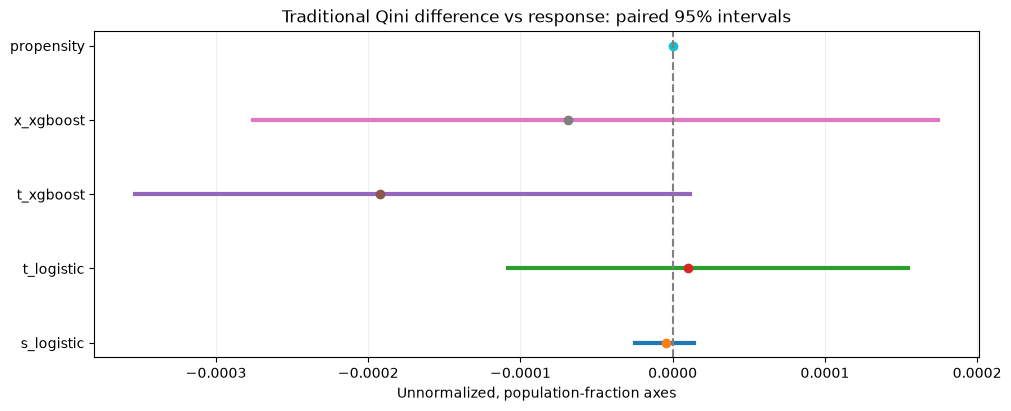

In [4]:
MET = result_directory('metrics_v2', ROOT)
ranking = pd.read_csv(MET / 'ranking.csv')
intervals = pd.read_csv(MET / 'ranking_intervals.csv')

ranking_cols = [c for c in [
    'policy', 'auuc_plugin', 'auuc_ht', 'qini_score_traditional',
    'qini_ht', 'relative_lift'
] if c in ranking.columns]
display(ranking[ranking_cols])

interval_cols = [c for c in [
    'metric', 'policy', 'estimate', 'ci_low', 'ci_high',
    'vs_propensity', 'vs_propensity_ci_low', 'vs_propensity_ci_high'
] if c in intervals.columns]
display(intervals[interval_cols])

chosen = intervals[intervals.metric == 'qini_score_traditional'].copy()
fig, ax = plt.subplots(figsize=(10, 4), layout='constrained')
for i, row in enumerate(chosen.itertuples()):
    ax.plot([row.vs_propensity_ci_low, row.vs_propensity_ci_high], [i, i], lw=3)
    ax.plot(row.vs_propensity, i, 'o')
ax.axvline(0, color='gray', ls='--')
ax.set_yticks(range(len(chosen)), chosen.policy)
ax.set(title='Traditional Qini difference vs response: paired 95% intervals', xlabel='Unnormalized, population-fraction axes')
ax.grid(axis='x', alpha=.2)
fig.savefig(FIG / 'qini_paired_intervals.png', dpi=160)
plt.show()

## 3. SQL：核对 Python 评价口径

**实现位置：** scripts/run_sql_audit.py → criteo_uplift/sql_audit.py；结果目录 sql_audit_v1/。

SQL 从公开 CSV 派生 SQLite 表，核对主键/外键、1:1 完整连接、两臂 CVR、十分位分桶和预算排名。row_id 是原始行号，不是真实用户 ID，也没有伪造事件时间。完整查询保存在 artifacts/sql_audit_v1/queries.sql；Notebook 只展示关键核对结果，不把整份 SQL 原文铺在输出区。

In [5]:
SQL = result_directory('sql_audit_v1', ROOT)
display(pd.read_csv(SQL / 'join_integrity.csv'))
display(pd.read_csv(SQL / 'cvr.csv'))
display(pd.read_csv(SQL / 'policy_values.csv'))
display(pd.read_csv(SQL / 'score_bins.csv').head(12))

queries_path = SQL / 'queries.sql'
query_text = queries_path.read_text()
statement_count = query_text.count(';')
print(f"完整 SQL：{queries_path.relative_to(ROOT)}")
print(f"查询文件行数：{len(query_text.splitlines())}；分号结尾语句数：{statement_count}")
print("Notebook 只展示审计结果；需要逐句学习 SQL 时打开上述 queries.sql 文件。")

,table_pair,policy,assignment_rows,outcome_rows,joined_rows,missing_outcomes,orphan_outcomes,score_rows,distinct_score_rows,missing_scores
0,assignment_outcome,NaN,200000.0,200000.0,200000,0.0,0.0,NaN,NaN,NaN
1,assignment_outcome_scores,s_logistic,NaN,NaN,200000,NaN,NaN,200000.0,200000.0,0.0
2,assignment_outcome_scores,t_logistic,NaN,NaN,200000,NaN,NaN,200000.0,200000.0,0.0
3,assignment_outcome_scores,t_xgboost,NaN,NaN,200000,NaN,NaN,200000.0,200000.0,0.0
4,assignment_outcome_scores,x_xgboost,NaN,NaN,200000,NaN,NaN,200000.0,200000.0,0.0
5,assignment_outcome_scores,propensity,NaN,NaN,200000,NaN,NaN,200000.0,200000.0,0.0


,n,n_treatment,n_control,responses_treatment,responses_control,cvr_treatment,cvr_control,difference_in_means,ate_ht
0,200000,170082,29918,522,55,0.003069,0.001838,0.001231,0.001231


,policy,budget,n_eligible,n_selected,selected_fraction,sql_incremental_per_100k,python_incremental_per_100k,sql_minus_python,vs_random_per_100k,selected_on_validation
0,random,0.2,200000,40000,0.2,24.614993,24.614993,0.000000e+00,0.000000,False
1,s_logistic,0.2,200000,40000,0.2,123.324666,123.324666,9.521273e-13,98.709673,False
2,t_logistic,0.2,200000,40000,0.2,126.328883,126.328883,8.384404e-13,101.713890,False
3,t_xgboost,0.2,200000,40000,0.2,95.352684,95.352684,6.110668e-13,70.737691,False
4,x_xgboost,0.2,200000,40000,0.2,110.115936,110.115936,5.826450e-13,85.500942,False
5,propensity,0.2,200000,40000,0.2,117.227679,117.227679,7.531753e-13,92.612686,True


,policy,score_bin,n,first_rank,last_rank,mean_score,min_score,max_score,n_treatment,n_control,responses_treatment,responses_control,cvr_treatment,cvr_control,observed_uplift,incremental_per_100k_eligible
0,s_logistic,1,20000,1,20000,0.008981,0.001116,0.138409,17275,2725,461,47,0.026686,0.017248,0.009438,113.949668
1,s_logistic,2,20000,20001,40000,0.000675,0.000445,0.001116,17095,2905,33,3,0.001930,0.001033,0.000898,9.374998
2,s_logistic,3,20000,40001,60000,0.000362,0.000302,0.000445,16972,3028,8,0,0.000471,0.000000,0.000471,4.703614
3,s_logistic,4,20000,60001,80000,0.000264,0.000233,0.000302,16948,3052,5,3,0.000295,0.000983,-0.000688,-7.087650
4,s_logistic,5,20000,80001,100000,0.000211,0.000194,0.000233,16973,3027,4,1,0.000236,0.000330,-0.000095,-0.990663
5,s_logistic,6,20000,100001,120000,0.000181,0.000170,0.000194,17049,2951,2,0,0.000117,0.000000,0.000117,1.175903
6,s_logistic,7,20000,120001,140000,0.000162,0.000154,0.000170,16890,3110,1,1,0.000059,0.000322,-0.000262,-2.754518
7,s_logistic,8,20000,140001,160000,0.000147,0.000139,0.000154,16938,3062,5,0,0.000295,0.000000,0.000295,2.939758
8,s_logistic,9,20000,160001,180000,0.000131,0.000123,0.000139,16974,3026,0,0,0.000000,0.000000,0.000000,0.000000
9,s_logistic,10,20000,180001,200000,0.000106,0.000045,0.000123,16968,3032,3,0,0.000177,0.000000,0.000177,1.763855


完整 SQL：reports/published/sql_audit_v1/queries.sql
查询文件行数：114；分号结尾语句数：11
Notebook 只展示审计结果；需要逐句学习 SQL 时打开上述 queries.sql 文件。


## 4. 样本量与成本/价值情景

**实现位置：** criteo_uplift/planning.py 的 plan_policy_ab() 与 cost_value_scenario()。

本节输入的基线率、MDE、每次转化价值和单次触达成本都是显式假设，不是 Criteo 的真实线上 CVR、收入或成本。样本量按全部入组人群定义的策略效果计算；预算比例决定触达人数，不能直接拿预算比例除以 MDE。经济情景只回答“如果这些假设成立，结果会怎样”，不能当作已实现 ROI。

In [6]:
from criteo_uplift.planning import plan_policy_ab, cost_value_scenario

plans = pd.DataFrame([plan_policy_ab(.003, delta) for delta in [.00015, .0003, .0006]])
plan_columns = [
    'p0_assumed', 'p1_assumed', 'absolute_mde', 'relative_mde',
    'n_policy_B', 'n_policy_A', 'n_total', 'approximate_achieved_power'
]
display(plans[plan_columns])

RUN = result_directory('conversion_1000000_seed42', ROOT)
policy_results = pd.read_csv((RUN / 'evaluation' / 'test_policies.csv'))
selection = json.loads(((RUN / 'models' / 'selection.json')).read_text())
row = policy_results[
    (policy_results.policy == selection['selected_policy']) &
    np.isclose(policy_results.budget, .2)
].iloc[0]

scenarios = []
for value in [1., 5., 10.]:
    for cost in [.001, .01, .05]:
        scenarios.append(cost_value_scenario(
            float(row.incremental_per_100k), budget=.2,
            value_per_conversion=value, contact_cost=cost,
            ci_low=float(row.ci_low), ci_high=float(row.ci_high)
        ))
scenario_table = pd.DataFrame(scenarios)
scenario_columns = [
    'budget', 'contacts', 'value_per_conversion_assumed', 'contact_cost_assumed',
    'gross_incremental_value', 'contact_cost_total', 'net_incremental_value',
    'net_ci_low_conditional', 'net_ci_high_conditional', 'break_even_contact_cost'
]
display(scenario_table[scenario_columns])
print('所有成本、价值和效果迁移都来自假设输入，不是实际收入或 ROI。')

,p0_assumed,p1_assumed,absolute_mde,relative_mde,n_policy_B,n_policy_A,n_total,approximate_achieved_power
0,0.003,0.00315,0.00015,0.05,2138763,2138763,4277526,0.800001
1,0.003,0.00330,0.00030,0.10,547690,547690,1095380,0.800001
2,0.003,0.00360,0.00060,0.20,143421,143421,286842,0.800003


,budget,contacts,value_per_conversion_assumed,contact_cost_assumed,gross_incremental_value,contact_cost_total,net_incremental_value,net_ci_low_conditional,net_ci_high_conditional,break_even_contact_cost
0,0.2,20000,1.0,0.001,117.227679,20.0,97.227679,44.092311,146.214162,0.005861
1,0.2,20000,1.0,0.010,117.227679,200.0,-82.772321,-135.907689,-33.785838,0.005861
2,0.2,20000,1.0,0.050,117.227679,1000.0,-882.772321,-935.907689,-833.785838,0.005861
3,0.2,20000,5.0,0.001,586.138394,20.0,566.138394,300.461555,811.070810,0.029307
4,0.2,20000,5.0,0.010,586.138394,200.0,386.138394,120.461555,631.070810,0.029307
5,0.2,20000,5.0,0.050,586.138394,1000.0,-413.861606,-679.538445,-168.929190,0.029307
6,0.2,20000,10.0,0.001,1172.276788,20.0,1152.276788,620.923109,1642.141620,0.058614
7,0.2,20000,10.0,0.010,1172.276788,200.0,972.276788,440.923109,1462.141620,0.058614
8,0.2,20000,10.0,0.050,1172.276788,1000.0,172.276788,-359.076891,662.141620,0.058614


所有成本、价值和效果迁移都来自假设输入，不是实际收入或 ROI。


## 5. 当前证据支持什么、不支持什么

1. 当前公开基准上，冻结的 response propensity 策略在 20% 预算下高于解析随机策略；这不是线上收入增长声明。
2. S/T/X learner 均已实现，但当前结果没有证明复杂 X-Learner 优于 response 基线；开发期配置也没有显示反转。
3. 现有学习曲线不能单独证明“扩样就会解决”；500 万/全量重训和线上策略实验尚未完成。
4. 真正上线前，需要预先冻结候选池、策略、转化窗口、主指标、成本护栏和停止规则，并通过独立线上随机实验验证。

完整的代码调用关系见 ../docs/PROJECT_PIPELINE.md；结果文件和对外表达边界见 ../docs/RESULTS_GUIDE.md。